# Imports

In [85]:
pip install dcor

Note: you may need to restart the kernel to use updated packages.


In [86]:
pip install factor-analyzer

Note: you may need to restart the kernel to use updated packages.


In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import os
import itertools
import statsmodels.api as sm
from scipy import stats
from scipy.stats import pearsonr
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import dcor
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings("ignore")

In [88]:
##change here as needed
base_path = "/Users/avagrossman/Desktop/CST"
dependent_var = "Median"
independent_vars = ['REAL_GDP_1_YR_GR',
               'UNEMP_RATE_1_YR_CH', 
               'WTI_PRICE_1_YR_GR',
               'CPI_1_YR_GR',
               'THREE_MONTH_TREAS_RATE_1_YR_CH','FIVE_YEAR_TREAS_YIELD_1_YR_CH','TEN_YEAR_TREAS_YIELD_1_YR_CH', 
               'BBB_CORP_YIELD_1_YR_CH',
               'HPI_1_YR_GR',
               'SP_500_1_YR_GR']

In [89]:
data = pd.read_excel(os.path.join(base_path,"all_data.xlsx"))
data.head()

,REAL_GDP_1_YR_GR,UNEMP_RATE_1_YR_CH,WTI_PRICE_1_YR_GR,CPI_1_YR_GR,THREE_MONTH_TREAS_RATE_1_YR_CH,FIVE_YEAR_TREAS_YIELD_1_YR_CH,TEN_YEAR_TREAS_YIELD_1_YR_CH,BBB_CORP_YIELD_1_YR_CH,HPI_1_YR_GR,SP_500_1_YR_GR,Median,Year
0,0.048831,-0.3,-0.312181,-0.070078,-0.77,-1.15,-1.10,-2.26,0.060512,0.204638,0.12344,1998
1,0.048236,-0.4,1.121911,-0.110744,0.81,1.80,1.80,0.85,0.071316,0.228553,0.12732,1999
2,0.029056,-0.1,0.037267,0.370986,0.57,-1.37,-1.33,-0.68,0.085015,0.124033,0.12634,2000
3,0.001673,1.8,-0.252994,0.199466,-4.08,-0.61,-0.05,-1.10,0.062574,-0.067354,0.03882,2001
4,0.019925,0.3,0.563627,-0.216767,-0.50,-1.60,-1.24,1.80,0.087281,-0.171389,0.02251,2002


## Macroeconomic Data (Independent Variables)

In [90]:
data.describe()[independent_vars]

,REAL_GDP_1_YR_GR,UNEMP_RATE_1_YR_CH,WTI_PRICE_1_YR_GR,CPI_1_YR_GR,THREE_MONTH_TREAS_RATE_1_YR_CH,FIVE_YEAR_TREAS_YIELD_1_YR_CH,TEN_YEAR_TREAS_YIELD_1_YR_CH,BBB_CORP_YIELD_1_YR_CH,HPI_1_YR_GR,SP_500_1_YR_GR
count,26.000000,26.000000,26.000000,26.000000,26.000000,26.000000,26.000000,26.000000,26.000000,26.000000
mean,0.023696,-0.034615,0.123560,0.096558,0.003077,-0.071923,-0.071923,-0.265769,0.045875,0.046034
std,0.017893,1.253776,0.398247,0.459527,1.542846,1.106161,1.028082,1.001931,0.064125,0.188214
min,-0.025412,-2.800000,-0.535175,-0.495593,-4.080000,-1.900000,-1.790000,-2.260000,-0.136308,-0.592874
25%,0.016620,-0.600000,-0.182686,-0.168172,-0.447500,-1.067500,-0.845000,-0.960000,0.037418,-0.051068
50%,0.026602,-0.300000,0.066579,0.038896,0.040000,0.005000,-0.040000,-0.080000,0.056051,0.111792
75%,0.032656,0.200000,0.394696,0.192341,0.810000,0.447500,0.312500,0.262500,0.086715,0.181003
max,0.057562,3.100000,1.121911,1.461630,4.190000,2.730000,2.360000,1.800000,0.158688,0.229623


## Dependent Variable

In [91]:
revenue = data[[dependent_var, 'Year']]
revenue.Year= pd.to_datetime(revenue.Year,format="%Y")
revenue.Year=revenue.Year.dt.year
revenue.head()

,Median,Year
0,0.12344,1998
1,0.12732,1999
2,0.12634,2000
3,0.03882,2001
4,0.02251,2002


In [92]:
len(data)
data.to_excel(os.path.join(base_path,"all_data_2.xlsx"))

In [93]:
macro_revenue_merged = data.dropna()
print(len(macro_revenue_merged))
print("Years with revenue (dependent var) data", macro_revenue_merged.Year.values)

26
Years with revenue (dependent var) data [1998 1999 2000 2001 2002 2003 2004 2005 2006 2007 2008 2009 2010 2011
 2012 2013 2014 2015 2016 2017 2018 2019 2020 2021 2022 2023]


## Approach 1: Correlation Matrix

In [94]:
dependent_var = "Median"

#use CH for yields &rates 
correlation_columns = ['REAL_GDP_1_YR_GR',
                       'UNEMP_RATE_1_YR_CH', 
                       'WTI_PRICE_1_YR_GR',
                       'CPI_1_YR_GR',
                       'THREE_MONTH_TREAS_RATE_1_YR_CH','FIVE_YEAR_TREAS_YIELD_1_YR_CH','TEN_YEAR_TREAS_YIELD_1_YR_CH', 
                       'BBB_CORP_YIELD_1_YR_CH',
                       'HPI_1_YR_GR',
                       'SP_500_1_YR_GR',
                       dependent_var] 
#make dataframe
macro_merged = macro_revenue_merged[correlation_columns]

# Select numeric variables
df_num = macro_merged.select_dtypes(include=[np.number]).copy()

# Method 1: pandas
corr_pandas = df_num.corr(method="spearman")

# Method 2: scipy pairwise pearsonr
corr_scipy = pd.DataFrame(
    np.nan,
    index=df_num.columns,
    columns=df_num.columns
)
print("Max absolute difference:")
print(diff.max().max())

print("\nPandas correlations with dependent variable:")
print(
    corr_pandas[dependent_var]
    .drop(dependent_var)
    .sort_values(key=lambda x: x.abs(), ascending=False)
)


Max absolute difference:
nan

Pandas correlations with dependent variable:
REAL_GDP_1_YR_GR                  0.502906
SP_500_1_YR_GR                    0.487179
CPI_1_YR_GR                       0.446154
THREE_MONTH_TREAS_RATE_1_YR_CH    0.316923
UNEMP_RATE_1_YR_CH               -0.305742
HPI_1_YR_GR                       0.208889
FIVE_YEAR_TREAS_YIELD_1_YR_CH     0.208205
BBB_CORP_YIELD_1_YR_CH           -0.171282
WTI_PRICE_1_YR_GR                 0.154188
TEN_YEAR_TREAS_YIELD_1_YR_CH      0.076239
Name: Median, dtype: float64


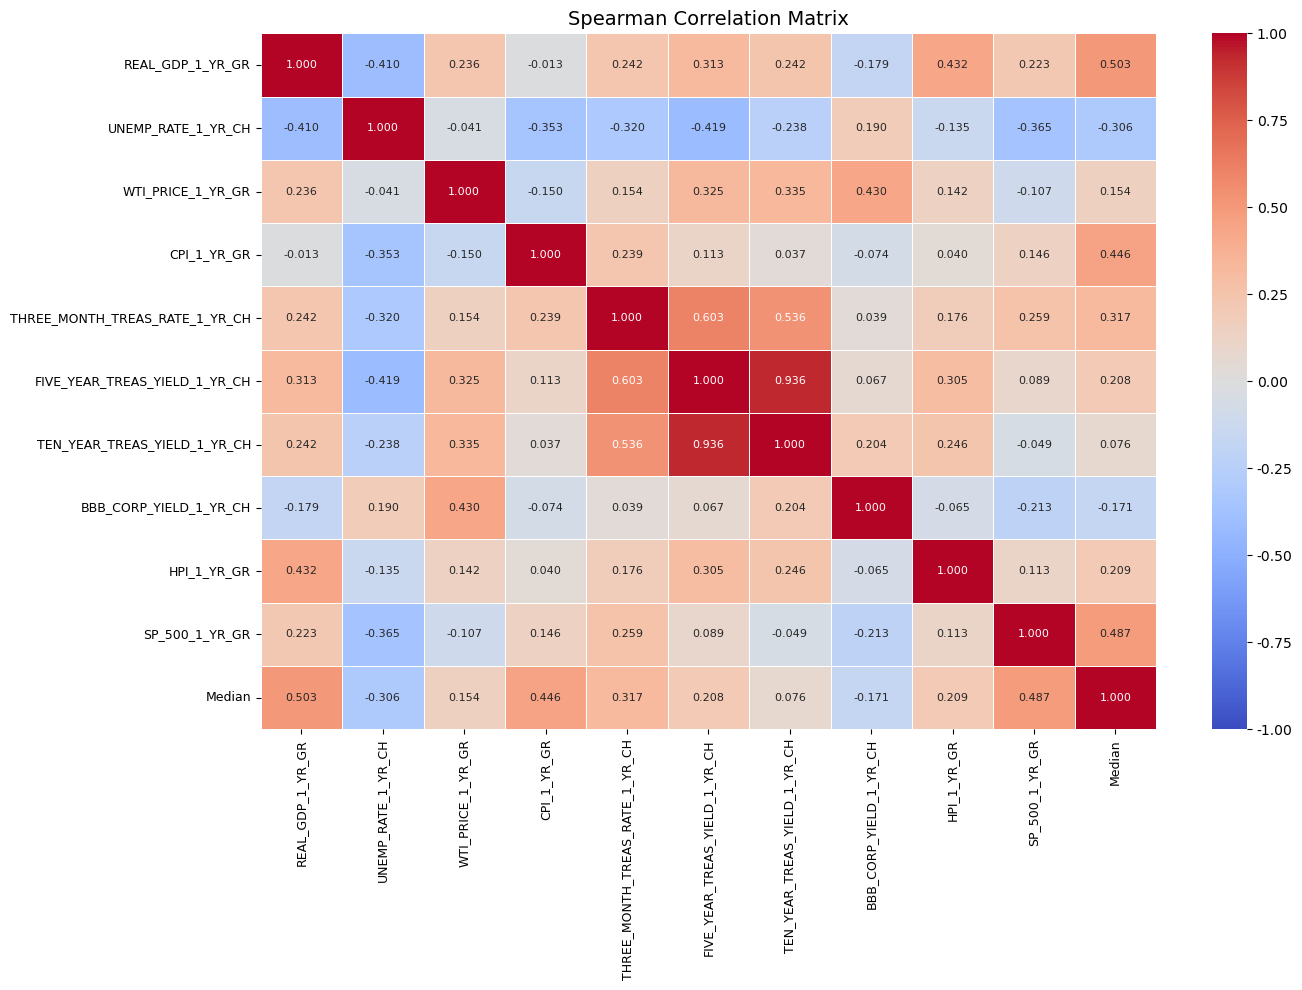

In [79]:
# Spearman correlation matrix
corr_matrix = macro_merged.corr(method="spearman")

plt.figure(figsize=(14, 10)) 

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",               
    annot_kws={"size": 8},
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"format": "%.2f"}
)

plt.title("Spearman Correlation Matrix", fontsize=14)
plt.xticks(rotation=90, ha="center", fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.tight_layout()
#plt.savefig(os.path.join(base_path, "correlation_matrix_all.png"),bbox_inches="tight",dpi=300)
plt.show()

In [80]:
#The correlation coefficient converts to a Student's t-distribution using (n - 2) degrees of freedom
#sig level = .05

def calculate_min_r_threshold(n, alpha=0.05):
    """
    Calculates the minimum absolute correlation coefficient 
    required to reject the null hypothesis.
    """
    
    df = n - 2 # Degrees of freedom
    # Find critical t-value for a two-tailed test
    t_critical = stats.t.ppf(1 - alpha/2, df)
    # Solve for critical r
    r_critical = t_critical / np.sqrt(t_critical**2 + df)
    return (r_critical,df)

n = len(macro_merged.dropna()) ##26, includes y
threshold,df = calculate_min_r_threshold(n)
print("Threshold for feature selection: ", threshold, " with ", df, " degrees of freedom" )

target_corr = macro_merged.corr(method="spearman")[dependent_var].abs().drop(dependent_var)
candidate_features = target_corr[target_corr >= threshold].index.tolist()
print("Candidate features given threshold: ", candidate_features)

Threshold for feature selection:  0.3882439970172523  with  24  degrees of freedom
Candidate features given threshold:  ['REAL_GDP_1_YR_GR', 'CPI_1_YR_GR', 'SP_500_1_YR_GR']


In [81]:
#Iteratively drop the highest VIF feature until all remaining are below threshold
vif_threshold = 5.0

print("\n---------VIF---------")
print("Using VIF threshold of:", vif_threshold)

candidate_features_vif = candidate_features.copy()

while True:
    # Drop missing values from the subset
    macro_merged_subset = macro_merged[candidate_features_vif].dropna()
    
    # Add an intercept/constant column for accurate VIF calculation
    # prepend=True puts 'const' at column index 0
    macro_merged_with_const = add_constant(macro_merged_subset, prepend=True)
    
    # Calculate VIF for all current candidates
    vif_data = pd.DataFrame()
    vif_data["feature"] = candidate_features_vif
    vif_data["VIF"] = [
        variance_inflation_factor(macro_merged_with_const.values, i) 
        for i in range(1, len(macro_merged_with_const.columns))
    ]
    
    print("---------------------")
    print(vif_data)
    print("---------------------")
    
    # Find the worst offending feature
    max_vif = vif_data["VIF"].max()
    
    if max_vif > vif_threshold:
        # Identify the feature name with the maximum VIF
        worst_feature = vif_data.sort_values("VIF", ascending=False).iloc[0]["feature"]
        candidate_features_vif.remove(worst_feature)
        print(f"Dropped {worst_feature} with VIF {max_vif:.3f}")
    else:
        break

print("Final clean feature set:", candidate_features_vif)


---------VIF---------
Using VIF threshold of: 5.0
---------------------
            feature       VIF
0  REAL_GDP_1_YR_GR  1.070576
1       CPI_1_YR_GR  1.126767
2    SP_500_1_YR_GR  1.176617
---------------------
Final clean feature set: ['REAL_GDP_1_YR_GR', 'CPI_1_YR_GR', 'SP_500_1_YR_GR']


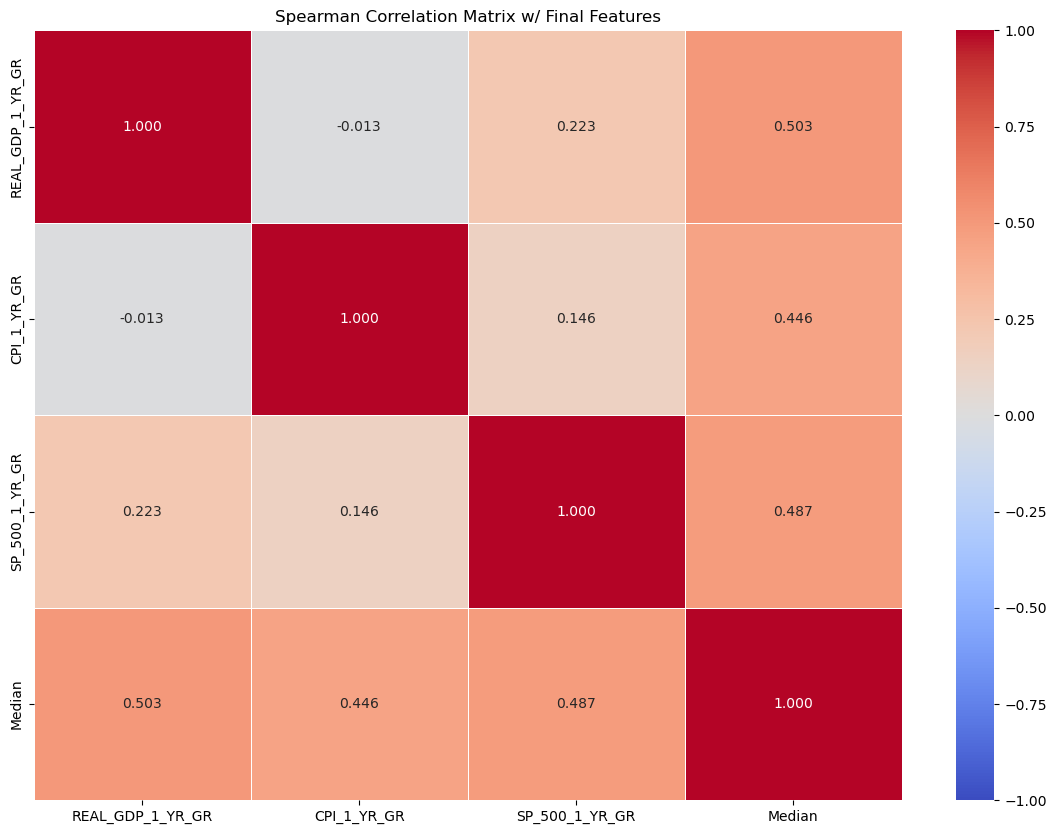

In [82]:
if dependent_var not in candidate_features:
    candidate_features.append(dependent_var)

corr_matrix_2= macro_merged[candidate_features].dropna().corr(method="spearman")

plt.figure(figsize=(14, 10)) 
# Generate a styled heatmap using Seaborn
sns.heatmap(
    corr_matrix_2, 
    annot=True,          
    cmap='coolwarm',     
    fmt=".3f",           
    vmin=-1, vmax=1,     
    linewidths=0.5      
)

plt.title("Spearman Correlation Matrix w/ Final Features")
#plt.savefig(os.path.join(base_path,"correlation_matrix_vF.png"), bbox_inches='tight',dpi=300)
plt.show()

## Approach 2: Cluster

In [83]:
dependent_var = "Median"
#use CH for yields &rates 
features = ['REAL_GDP_1_YR_GR',
            'UNEMP_RATE_1_YR_CH', 
            'WTI_PRICE_1_YR_GR',
            'CPI_1_YR_GR',
            'THREE_MONTH_TREAS_RATE_1_YR_CH','FIVE_YEAR_TREAS_YIELD_1_YR_CH','TEN_YEAR_TREAS_YIELD_1_YR_CH', 
            'BBB_CORP_YIELD_1_YR_CH',
            'HPI_1_YR_GR',
            'SP_500_1_YR_GR'
           ]

silhouette sweep: {2: 0.152, 3: 0.213, 4: 0.18, 5: 0.288, 6: 0.239, 7: 0.186, 8: 0.157, 9: 0.17}
Chosen k = 5


Cluster 1  (3 vars)
   THREE_MONTH_TREAS_RATE_1_YR_CH      |rho with y| = 0.317  Maximum-target
   FIVE_YEAR_TREAS_YIELD_1_YR_CH       |rho with y| = 0.208  Medoid
   TEN_YEAR_TREAS_YIELD_1_YR_CH        |rho with y| = 0.076  

Cluster 2  (2 vars)
   REAL_GDP_1_YR_GR                    |rho with y| = 0.503  Medoid Maximum-target
   HPI_1_YR_GR                         |rho with y| = 0.209  

Cluster 3  (2 vars)
   WTI_PRICE_1_YR_GR                   |rho with y| = 0.154  Medoid
   BBB_CORP_YIELD_1_YR_CH              |rho with y| = 0.171  Maximum-target

Cluster 4  (2 vars)
   UNEMP_RATE_1_YR_CH                  |rho with y| = 0.306  Medoid
   SP_500_1_YR_GR                      |rho with y| = 0.487  Maximum-target

Cluster 5  (1 vars)
   CPI_1_YR_GR                         |rho with y| = 0.446  Medoid Maximum-target

Medoid selection     : ['CPI_1_YR_GR', 'FIVE_YEAR_TREAS_YIELD

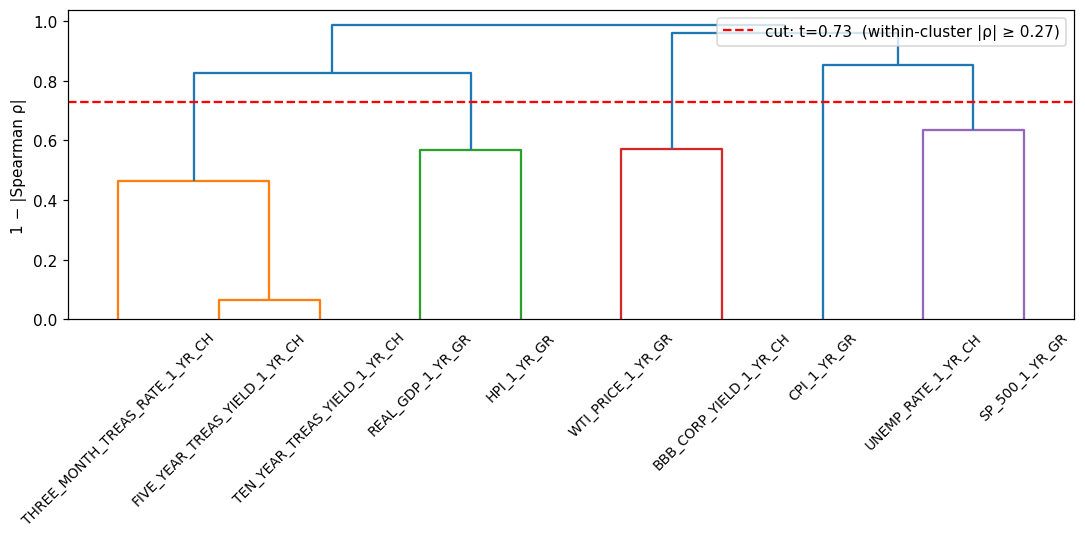


VIF (Medoid): 
UNEMP_RATE_1_YR_CH               4.847
REAL_GDP_1_YR_GR                 4.031
CPI_1_YR_GR                      1.704
WTI_PRICE_1_YR_GR                1.408
FIVE_YEAR_TREAS_YIELD_1_YR_CH    1.304
dtype: float64

VIF (Maximum-target): 
THREE_MONTH_TREAS_RATE_1_YR_CH    1.253
REAL_GDP_1_YR_GR                  1.253
SP_500_1_YR_GR                    1.206
CPI_1_YR_GR                       1.180
BBB_CORP_YIELD_1_YR_CH            1.085
dtype: float64


In [84]:
# ---------- Data ----------
X = macro_revenue_merged[features].dropna()          
y = macro_revenue_merged.loc[X.index, dependent_var]      

# ----------Spearman -> distance ----------
A = X.corr(method='spearman').abs()
D = 1 - A.values
#np.clip forcing the matrix to be symmetric.
D = np.clip((D + D.T) / 2, 0, None); np.fill_diagonal(D, 0)

# ----------Complete linkage ----------
Z = linkage(squareform(D, checks=False), method='complete')

# --------Silhouette picks k using the precomputed values from step 1 ----------
sil = {k: silhouette_score(
                        D, 
                        fcluster(Z, k, criterion='maxclust'),
                        metric='precomputed') 
                        for k in range(2, len(features))
      }
print(f"silhouette sweep: { {k: round(v,3) for k,v in sil.items()} }")
k_opt = max(sil, key=sil.get)
labels = fcluster(Z, k_opt, criterion='maxclust')
print(f"Chosen k = {k_opt}\n")

# ----------Cluster results ----------
clusters = pd.Series(labels, index=X.columns, name='cluster')
Ddf = pd.DataFrame(D, index=X.columns, columns=X.columns)
target_corr = X.corrwith(y, method='spearman').abs()
print("=" * 100)

#iterate through each cluster (cid)
for cid in np.unique(labels):
    #members: Identifies all variables (features) assigned to the current cluster.
    members = clusters[clusters == cid].index
    #sub: Extracts a mini-correlation matrix containing only the variables inside this cluster.
    sub = A.loc[members, members].values
    #min_rho: Finds the weakest absolute correlation between any two variables inside this cluster.
    min_rho = sub[np.triu_indices(len(members), 1)].min() if len(members) > 1 else np.nan
    #medoid: The variable closest to the "center" of the cluster.
    #The variable with the lowest total distance to all other members is the medoid.
    medoid = Ddf.loc[members, members].sum().idxmin()
    #best_tc: The variable in the cluster that has the strongest relationship with y.
    best_tc = target_corr[members].idxmax()
    #print the cluster ID and vars 
    print(f"\nCluster {cid}  ({len(members)} vars)")
    #loop through every var (v) in the cluster, with its correlation to y.
    for v in members:
        tags = []
        #add mediod or max corr w/ y label if applicable
        if v == medoid:  tags.append("Medoid")
        if v == best_tc: tags.append("Maximum-target")
        print(f"   {v:<35} |rho with y| = {target_corr[v]:.3f}"
              f"  {' '.join(tags)}")
#sel_medoid: A list of the central variables from each cluster. 
sel_medoid = [Ddf.loc[m, m].sum().idxmin()
              for cid in np.unique(labels)
              if len(m := clusters[clusters == cid].index) > 0]
#sel_target: A list of the variables from each cluster that are most predictive of y.
sel_target = [target_corr[clusters[clusters == cid].index].idxmax()
              for cid in np.unique(labels)]
print("\n" + "=" * 70)
print(f"Medoid selection     : {sorted(sel_medoid)}")
print(f"Maximum-target selection : {sorted(sel_target)}")
print(f"agree: {set(sel_medoid) == set(sel_target)}")

# ----------Dendrogram with the cut ----------
#Extract height values from linkage matrix Z.
heights = Z[:, 2]
#Calculates t_cut as the average of two adjacent linkage heights.
t_cut = (heights[-k_opt] + heights[-k_opt + 1]) / 2   # height giving k_opt
plt.figure(figsize=(10, 5), dpi=110)
dendrogram(Z, labels=X.columns.tolist(), leaf_rotation=45, leaf_font_size=9,
           color_threshold=t_cut)

plt.axhline(t_cut, color='r', ls='--', lw=1.5,
            label=f'cut: t={t_cut:.2f}  (within-cluster |ρ| ≥ {1-t_cut:.2f})')

plt.ylabel('1 − |Spearman ρ|'); plt.legend(); plt.tight_layout(); plt.show()

# ----------VIF on the selected set (correct usage: raw data + const) ----------

for name, sel in [('Medoid', sel_medoid), ('Maximum-target', sel_target)]:
    W = sm.add_constant(X[sel])
    vifs = pd.Series([variance_inflation_factor(W.values, i)
                      for i in range(1, W.shape[1])], index=sel)
    print(f"\nVIF ({name}): \n{vifs.round(3).sort_values(ascending=False)}")


### Cluster Logic

In [36]:
dependent_var = "Median"
#use CH for yields &rates 
features = ['REAL_GDP_1_YR_GR',
                       'UNEMP_RATE_1_YR_CH', 
                       'WTI_PRICE_1_YR_GR',
                       'CPI_1_YR_GR',
                       'THREE_MONTH_TREAS_RATE_1_YR_CH','FIVE_YEAR_TREAS_YIELD_1_YR_CH','TEN_YEAR_TREAS_YIELD_1_YR_CH', 
                       'BBB_CORP_YIELD_1_YR_CH',
                       'HPI_1_YR_GR',
                       'SP_500_1_YR_GR']

X = macro_revenue_merged[features].dropna() 
#The Purpose: Distance correlation can detect nonlinear patterns (like sinusoids, quadratic curves, or circles) 
#If two variables are independent, dCor is exactly 0; 
#if they are related in any shape, it is >0.

def dcor_matrix(X):
    p = X.shape[1]
    M = np.eye(p) # diagonal = 1 (self-dCor)
    for i in range(p):
        for j in range(i + 1, p):
            v2 = dcor.u_distance_correlation_sqr(
                X.iloc[:, i].to_numpy(float), X.iloc[:, j].to_numpy(float))
            M[i, j] = M[j, i] = np.sqrt(max(v2, 0.0))   # clip, then sqrt
    return pd.DataFrame(M, index=X.columns, columns=X.columns)

#create distances across 4 methods:
#Pearson: Measures linear relationships.
#Spearman: Measures monotonic/rank relationships.
#Kendall: Measures ordinal/ranked concordant pairs.
#dCor: Measures linear and nonlinear relationships.

dists = {}
for m in ['pearson', 'spearman', 'kendall']:
    dists[m] = 1 - X.corr(method=m).abs().values

dists['dcor'] = 1 - dcor_matrix(X).values

#prepare matrix
for m in dists:                               
    D = dists[m]
    D = np.clip((D + D.T) / 2, 0, None)        # force exact symmetry, no <0
    np.fill_diagonal(D, 0.0)                   # squareform requires 0 diag
    dists[m] = D

#Use Complete-Linkage hierarchical clustering.
#Create four separate trees.
trees = {m: linkage(squareform(D,checks=False), method="complete") for m,D in dists.items()}
measures  = list(dists)

# Question: Does it matter which correlation metric I use to analyze my features?
lvl1 = pd.DataFrame(index=measures, columns = measures, dtype=float)
for a in measures:
    for b in measures:
            lvl1.loc[a,b] = np.corrcoef(squareform(dists[a]),squareform(dists[b]))[0,1]
#Answer:
#dcor and peason 0.897, proves that the relationships dcor is picking up are mostly just the linear ones pearson already found.
#spearman and kendall are nearly identical, can use either one
print(lvl1.round(3))

          pearson  spearman  kendall   dcor
pearson     1.000     0.883    0.865  0.897
spearman    0.883     1.000    0.985  0.834
kendall     0.865     0.985    1.000  0.828
dcor        0.897     0.834    0.828  1.000


In [37]:
#Question: How different do the clusters look at all k across metric types?
#Use The Adjusted Rand Index (ARI) to evaluate and compare the similarity between data clusterings. 
#a score near zero = random group assignments 
#a score of 1.0 for a perfect match
rows = []
for k in range(2, X.shape[1]):                
    labels = {m: fcluster(trees[m], k, criterion='maxclust') for m in measures}
    rows.append({'k': k, **{f'ARI(spearman,{m})':
                adjusted_rand_score(labels['spearman'], labels[m])
                for m in measures if m != 'spearman'}})
lvl2 = pd.DataFrame(rows).set_index('k')
print(lvl2.round(3))

#Results show choice of metric matters more at smaller cluster sizes (k= 2 to 4)

   ARI(spearman,pearson)  ARI(spearman,kendall)  ARI(spearman,dcor)
k                                                                  
2                  0.597                  0.597               0.000
3                  0.657                  0.657               0.000
4                  0.364                  0.432               0.364
5                  0.731                  0.360               0.615
6                  0.775                  0.775               0.775
7                  0.726                  0.726               0.726
8                  0.366                  1.000               0.366
9                  1.000                  1.000               1.000


In [38]:
#Question: If I change my metric, will my clusters look different?
def medoid_selection(D, cols, labels):
    Ddf = pd.DataFrame(D, index=cols, columns=cols)
    return sorted(Ddf.loc[members, members].sum().idxmin()
                  for cid in np.unique(labels)
                  if len(members := cols[labels == cid]) > 0)

#forcing a 4-cluster solution across all metrics
K = 4                                          
for m in measures:
    labels = fcluster(trees[m], K, criterion='maxclust')
    #print out the the medoids for each.
    print(f"{m:>9}: {medoid_selection(dists[m], X.columns, labels)}")

#Results show all clusters have:
    #1. CPI (INFLATION), 
    #2. 5 yr treasury yield (Monetary Policy / Interest Rate)
    #3. WTI. (COMMODITIES)
    #4. DISAGREEMENT (REAL ECONOMY / GROWTH)
        #Real GDP and Unemployment (inverse relationship)
        #HPI. (housing price index)

  pearson: ['CPI_1_YR_GR', 'FIVE_YEAR_TREAS_YIELD_1_YR_CH', 'REAL_GDP_1_YR_GR', 'WTI_PRICE_1_YR_GR']
 spearman: ['CPI_1_YR_GR', 'FIVE_YEAR_TREAS_YIELD_1_YR_CH', 'UNEMP_RATE_1_YR_CH', 'WTI_PRICE_1_YR_GR']
  kendall: ['CPI_1_YR_GR', 'FIVE_YEAR_TREAS_YIELD_1_YR_CH', 'HPI_1_YR_GR', 'WTI_PRICE_1_YR_GR']
     dcor: ['CPI_1_YR_GR', 'FIVE_YEAR_TREAS_YIELD_1_YR_CH', 'REAL_GDP_1_YR_GR', 'WTI_PRICE_1_YR_GR']


In [43]:
#repeat the same exercise as before but with 5 and 6 clusters
candidate_K = [5, 6]

print("=" * 90)
print("             DYNAMIC METRIC MEDOID CROSS-COMPARISON")
print("=" * 90)

for k_val in candidate_K:
    print(f"\n▲ MEDOIDS FOR K = {k_val} CLUSTERS:")
    print("-" * 90)
    
    for m in measures:
        labels = fcluster(trees[m], k_val, criterion='maxclust')
        selected_features = medoid_selection(dists[m], X.columns, labels)
        print(f"  {m:>9}: {selected_features}")
    print("-" * 90)
#At k=6 all approaches provide same clusters medoids

             DYNAMIC METRIC MEDOID CROSS-COMPARISON

▲ MEDOIDS FOR K = 5 CLUSTERS:
------------------------------------------------------------------------------------------
    pearson: ['CPI_1_YR_GR', 'FIVE_YEAR_TREAS_YIELD_1_YR_CH', 'REAL_GDP_1_YR_GR', 'SP_500_1_YR_GR', 'WTI_PRICE_1_YR_GR']
   spearman: ['CPI_1_YR_GR', 'FIVE_YEAR_TREAS_YIELD_1_YR_CH', 'REAL_GDP_1_YR_GR', 'UNEMP_RATE_1_YR_CH', 'WTI_PRICE_1_YR_GR']
    kendall: ['CPI_1_YR_GR', 'FIVE_YEAR_TREAS_YIELD_1_YR_CH', 'HPI_1_YR_GR', 'SP_500_1_YR_GR', 'WTI_PRICE_1_YR_GR']
       dcor: ['CPI_1_YR_GR', 'FIVE_YEAR_TREAS_YIELD_1_YR_CH', 'HPI_1_YR_GR', 'REAL_GDP_1_YR_GR', 'WTI_PRICE_1_YR_GR']
------------------------------------------------------------------------------------------

▲ MEDOIDS FOR K = 6 CLUSTERS:
------------------------------------------------------------------------------------------
    pearson: ['CPI_1_YR_GR', 'FIVE_YEAR_TREAS_YIELD_1_YR_CH', 'HPI_1_YR_GR', 'REAL_GDP_1_YR_GR', 'SP_500_1_YR_GR', 'WTI_PRICE_1_YR_GR

In [44]:
#Question: I have selected spearman for my distance matrix, now what about my linkage matrix?
d = squareform(dists['spearman'], checks=False)

link_trees = {
    'complete':  linkage(d, method='complete'),
    'average':   linkage(d, method='average'),
    'ward_sqrt': linkage(np.sqrt(d), method='ward'),
    'single':    linkage(d, method='single'),
}

#ARI across linkages at each k. If the scores are high (near 1.0): The choice of algorithm does not alter your clusters much.
rows = []
for k in range(2, X.shape[1]):
    labels = {name: fcluster(Z, k, criterion='maxclust')
              for name, Z in link_trees.items()}
    rows.append({'k': k, **{f'ARI(complete,{n})':
                adjusted_rand_score(labels['complete'], labels[n])
                for n in link_trees if n != 'complete'}})
print(pd.DataFrame(rows).set_index('k').round(3))

# The Cophenetic Correlation Coefficient 
#A score of 1.0 means the tree perfectly matches your raw distance data.
#A score near 0.0 means the algorithm forced a fake hierarchy onto the data that doesn't actually exist.
from scipy.cluster.hierarchy import cophenet
for name, Z in link_trees.items():
    ref = np.sqrt(d) if name == 'ward_sqrt' else d
    print(f"{name:>9}: cophenetic = {cophenet(Z, ref)[0]:.3f}")

#Results: although average has a higher cophenetic score, for k=3 through k=6, Complete and Average linkage build the exact same clusters.

   ARI(complete,average)  ARI(complete,ward_sqrt)  ARI(complete,single)
k                                                                      
2                  0.096                    0.294                 0.096
3                  1.000                    0.378                 0.462
4                  1.000                    0.492                 0.692
5                  1.000                    1.000                 0.663
6                  1.000                    1.000                 1.000
7                  1.000                    1.000                 1.000
8                  1.000                    1.000                 1.000
9                  1.000                    1.000                 1.000
 complete: cophenetic = 0.819
  average: cophenetic = 0.836
ward_sqrt: cophenetic = 0.757
   single: cophenetic = 0.827


In [46]:
#compare average linkage silhouette and stability scores
Zc = link_trees['average']
D  = dists['spearman']
rng = np.random.default_rng(42) 

# Silhouette sweep
sil = {k: silhouette_score(D, fcluster(Zc, k, criterion='maxclust'),
                           metric='precomputed') for k in range(2, 9)}

stab = {}
for k in range(2, 9):
    ref = fcluster(Zc, k, criterion='maxclust')
    a = []
    for _ in range(500):
        Xb = X.iloc[rng.integers(0, len(X), len(X))]
        Db = 1 - Xb.corr(method='spearman').abs().values
        Db = np.clip((Db + Db.T)/2, 0, None); np.fill_diagonal(Db, 0)
        Zb = linkage(squareform(Db, checks=False), method='complete')
        a.append(adjusted_rand_score(ref, fcluster(Zb, k, criterion='maxclust')))
    stab[k] = np.mean(a)

print(pd.DataFrame({'silhouette': sil, 'stability': stab}).round(3))

   silhouette  stability
2       0.171      0.096
3       0.213      0.269
4       0.180      0.301
5       0.288      0.485
6       0.239      0.521
7       0.186      0.492
8       0.157      0.531


In [47]:
#compare complete silhouette and stability scores
Zc = link_trees['complete']
D  = dists['spearman']

# Silhouette sweep
sil = {k: silhouette_score(D, fcluster(Zc, k, criterion='maxclust'),
                           metric='precomputed') for k in range(2, 9)}

stab = {}
for k in range(2, 9):
    ref = fcluster(Zc, k, criterion='maxclust')
    a = []
    for _ in range(500):
        Xb = X.iloc[rng.integers(0, len(X), len(X))]
        Db = 1 - Xb.corr(method='spearman').abs().values
        Db = np.clip((Db + Db.T)/2, 0, None); np.fill_diagonal(Db, 0)
        Zb = linkage(squareform(Db, checks=False), method='complete')
        a.append(adjusted_rand_score(ref, fcluster(Zb, k, criterion='maxclust')))
    stab[k] = np.mean(a)

print(pd.DataFrame({'silhouette': sil, 'stability': stab}).round(3))

   silhouette  stability
2       0.152      0.155
3       0.213      0.269
4       0.180      0.296
5       0.288      0.469
6       0.239      0.496
7       0.186      0.502
8       0.157      0.505


## Approach 3: PCA

In [49]:
pca_columns = ['REAL_GDP_1_YR_GR',
               'UNEMP_RATE_1_YR_CH', 
               'WTI_PRICE_1_YR_GR',
               'CPI_1_YR_GR',
               'THREE_MONTH_TREAS_RATE_1_YR_CH',
               'FIVE_YEAR_TREAS_YIELD_1_YR_CH',
               'TEN_YEAR_TREAS_YIELD_1_YR_CH', 
               'BBB_CORP_YIELD_1_YR_CH',
               'HPI_1_YR_GR',
               'SP_500_1_YR_GR'] 

macro_pca = macro_revenue_merged[pca_columns]

X = macro_pca.copy()
X_centered = X - X.mean()

#same as standard scaler if ddof=0
std = X_centered.std(axis=0, ddof=1)
Z = X_centered / std  
Z = Z.reset_index(drop=True)
n = Z.shape[0]
p = Z.shape[1]
# --- SKLEARN ---
pca = PCA().fit(Z)

In [50]:
evals  = pca.explained_variance_
evr = pca.explained_variance_ratio_
cumsum_variance = np.cumsum(pca.explained_variance_ratio_)

# Calculate individual explained variance ratios
var_exp = evals / np.sum(evals)

# Calculate the cumulative sum of the variance ratios
cum_var_exp = np.cumsum(var_exp)

# Print the results side-by-side in a clean format
print(f"{'Component':<10} | {'Eigenvalue':<12} | {'Variance Ratio':<15} | {'Cumulative Variance':<20}")
print("-" * 67)
for i in range(len(evals)):
    print(f"PC {i+1:<7} | {evals[i]:<12.4f} | {var_exp[i]:<15.4f} | {cum_var_exp[i]:<20.4f}")

Component  | Eigenvalue   | Variance Ratio  | Cumulative Variance 
-------------------------------------------------------------------
PC 1       | 3.6674       | 0.3667          | 0.3667              
PC 2       | 2.1102       | 0.2110          | 0.5778              
PC 3       | 1.1560       | 0.1156          | 0.6934              
PC 4       | 0.9341       | 0.0934          | 0.7868              
PC 5       | 0.7130       | 0.0713          | 0.8581              
PC 6       | 0.5670       | 0.0567          | 0.9148              
PC 7       | 0.4262       | 0.0426          | 0.9574              
PC 8       | 0.3483       | 0.0348          | 0.9922              
PC 9       | 0.0619       | 0.0062          | 0.9984              
PC 10      | 0.0159       | 0.0016          | 1.0000              


Optimal number of components: 3


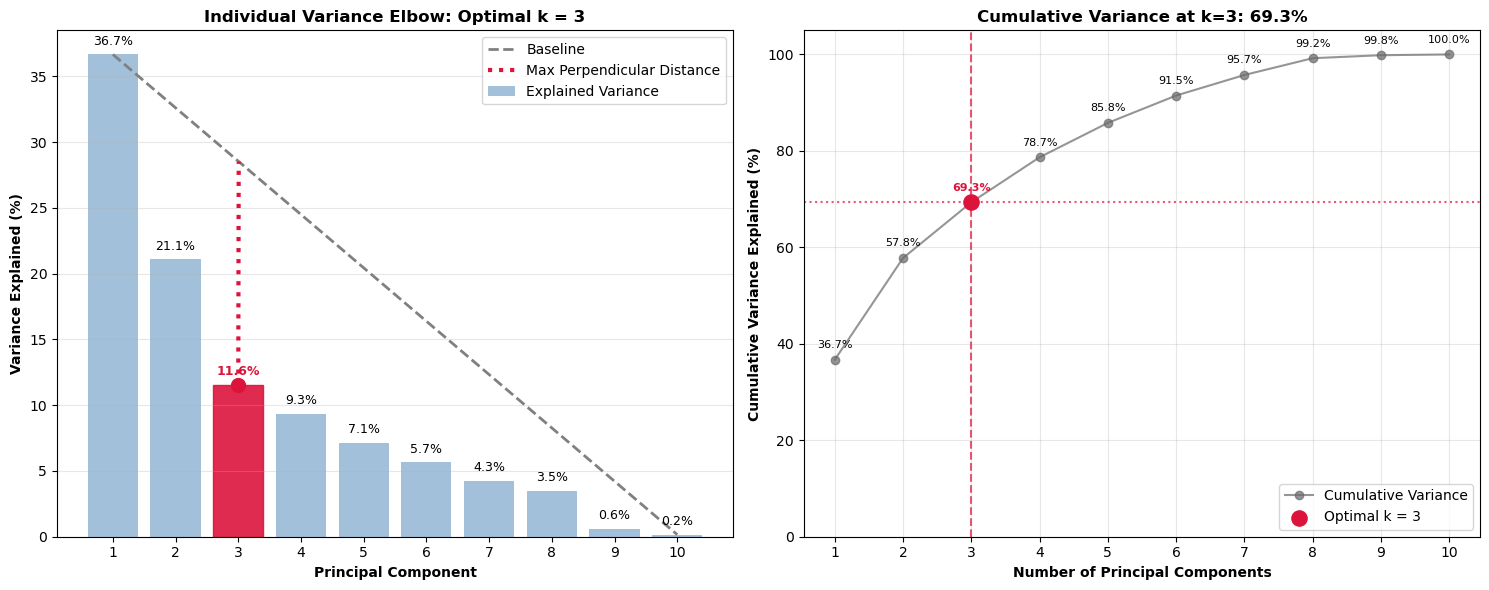

In [51]:
# Explained variance ratio from PCA
# evr = pca.explained_variance_ratio_

x = np.arange(1, len(evr) + 1)
y = evr

# -----------------------------
# Geometric elbow calculation
# -----------------------------

# First and last points of the curve
p1 = np.array([x[0], y[0]])
p2 = np.array([x[-1], y[-1]])

# Vector defining the baseline
line_vec = p2 - p1
line_len = np.linalg.norm(line_vec)

distances = []
projection_points = []

for xi, yi in zip(x, y):
    p = np.array([xi, yi])

    # Project point p onto the baseline
    t = np.dot(p - p1, line_vec) / np.dot(line_vec, line_vec)
    projection = p1 + t * line_vec

    # Perpendicular distance from p to the baseline
    distance = np.linalg.norm(p - projection)

    distances.append(distance)
    projection_points.append(projection)

distances = np.array(distances)
projection_points = np.array(projection_points)

# Optimal k is the component with maximum perpendicular distance
optimal_idx = np.argmax(distances)
optimal_n_components = x[optimal_idx]

print("Optimal number of components:", optimal_n_components)

# Cumulative variance
cumsum_variance = np.cumsum(evr)

# -----------------------------
# Plotting
# -----------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ax = axes[0]
bars = ax.bar(
    x,
    evr * 100,
    alpha=0.5,
    color="steelblue",
    label="Explained Variance"
)

# Highlight optimal component
bars[optimal_idx].set_color("crimson")
bars[optimal_idx].set_alpha(0.9)

# Baseline from first point to last point
ax.plot(
    [p1[0], p2[0]],
    [p1[1] * 100, p2[1] * 100],
    color="gray",
    linestyle="--",
    linewidth=2,
    label="Baseline"
)

# Perpendicular projection point for optimal k
optimal_point = np.array([x[optimal_idx], y[optimal_idx]])
optimal_projection = projection_points[optimal_idx]

# Draw actual perpendicular distance line
ax.plot(
    [optimal_point[0], optimal_projection[0]],
    [optimal_point[1] * 100, optimal_projection[1] * 100],
    color="crimson",
    linestyle=":",
    linewidth=3,
    label="Max Perpendicular Distance"
)

# Highlight optimal point
ax.scatter(
    optimal_point[0],
    optimal_point[1] * 100,
    color="crimson",
    s=100,
    zorder=5
)

# Annotate bars
for i, v in enumerate(evr * 100):
    ax.text(
        x[i],
        v + 0.5,
        f"{v:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold" if i == optimal_idx else "normal",
        color="crimson" if i == optimal_idx else "black"
    )

ax.set_xlabel("Principal Component", fontweight="bold")
ax.set_ylabel("Variance Explained (%)", fontweight="bold")
ax.set_title(
    f"Individual Variance Elbow: Optimal k = {optimal_n_components}",
    fontweight="bold"
)
ax.set_xticks(x)
ax.grid(alpha=0.3, axis="y")
ax.legend()

ax = axes[1]

ax.plot(
    x,
    cumsum_variance * 100,
    "o-",
    color="dimgray",
    linewidth=1.5,
    markersize=6,
    alpha=0.7,
    label="Cumulative Variance"
)

opt_cumsum = cumsum_variance[optimal_idx] * 100

ax.scatter(
    optimal_n_components,
    opt_cumsum,
    color="crimson",
    s=120,
    zorder=5,
    label=f"Optimal k = {optimal_n_components}"
)

ax.axvline(
    optimal_n_components,
    color="crimson",
    linestyle="--",
    alpha=0.7,
    linewidth=1.5
)

ax.axhline(
    opt_cumsum,
    color="crimson",
    linestyle=":",
    alpha=0.7,
    linewidth=1.5
)

for i, v in enumerate(cumsum_variance * 100):
    ax.text(
        x[i],
        v + 2,
        f"{v:.1f}%",
        ha="center",
        va="bottom",
        fontsize=8,
        fontweight="bold" if i == optimal_idx else "normal",
        color="crimson" if i == optimal_idx else "black"
    )

ax.set_xlabel("Number of Principal Components", fontweight="bold")
ax.set_ylabel("Cumulative Variance Explained (%)", fontweight="bold")
ax.set_title(
    f"Cumulative Variance at k={optimal_n_components}: {opt_cumsum:.1f}%",
    fontweight="bold"
)
ax.set_xticks(x)
ax.set_ylim(0, 105)
ax.grid(alpha=0.3)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()


In [52]:
#The Kaiser-Guttman Criterion: Retaining components with eigenvalues greater than 1.0 
#     (λ > 1.0). Since the data was z-score standardized, each original variable contributes 
#     a unit variance of 1.0. This criterion guarantees that every retained component 
#     explains more variance than any single un-transformed variable.
eigenvalues = pca.explained_variance_
selected = eigenvalues[eigenvalues > 1]
k_kg = len(selected)
print(f"Keep top {k_kg} components based on Eigenvalues > 1.0")

Keep top 3 components based on Eigenvalues > 1.0


In [55]:
#agreement on number of principal components to retain
k_sk =max(optimal_n_components, k_kg)
#calculate loadings for those principal components
sk_loadings = (pca.components_.T * np.sqrt(pca.explained_variance_))[:, :k_sk]

#calculate communality which is loadings ^2
sklearn_communalities = np.sum(sk_loadings**2, axis=1).round(3)

#sort descending
df_sk_results = pd.DataFrame(
    {"Extraction Communality": sklearn_communalities}, index=pca_columns
)
df_sk_results.sort_values("Extraction Communality",ascending=False)

,Extraction Communality
FIVE_YEAR_TREAS_YIELD_1_YR_CH,0.963
TEN_YEAR_TREAS_YIELD_1_YR_CH,0.925
UNEMP_RATE_1_YR_CH,0.830
REAL_GDP_1_YR_GR,0.812
WTI_PRICE_1_YR_GR,0.716
THREE_MONTH_TREAS_RATE_1_YR_CH,0.686
BBB_CORP_YIELD_1_YR_CH,0.547
SP_500_1_YR_GR,0.543
HPI_1_YR_GR,0.504
CPI_1_YR_GR,0.408
